# 01 · Preprocessing — Cohen et al. 2021 Multiple Myeloma (malignant compartment)

Isolate malignant plasma cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, and read **Gate 1**
(sample-mixing + manifold continuity) off the **regenerated embedding** plus a per-neighbourhood
metric (**iLISI**) across an integration-strength (`theta`) **and** `n_pcs` sweep — never a scalar alone.

Cohen 2021 is multiple myeloma profiled by **MARS-seq** across 73 malignant samples. Myeloma plasma
cells are strongly **patient-clonal** (each patient carries private CNV/Ig lesions), so raw
per-patient segregation is near-total and strong Harmony integration is required. This is exactly the
regime where Gate 1 can be mis-called on a global scalar: the decision here is made on the embedding
and per-neighbourhood iLISI. Every tunable choice is *derived from this dataset*, not inherited from
the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Cohen2021_Hematologic-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-2' re-analysis suffix
raw_name = 'Data_' + name.replace('-2','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Cohen2021_Hematologic-2 | category: Hematologic


In [3]:
# load dataset (single leaf dir; MARS-seq UMI counts -> normalize_total -> log1p by loader)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Cohen2021_Hematologic
Done.
full atlas: (39157, 57874)
malignant: (33599, 57874) | samples: 73
expression: X max 6.99 (log1p of normalize_total UMI counts)


In [4]:
# DERIVE per-sample threshold by gap-finding (not the inherited >=100 constant).
# Rule: sort per-sample counts; a *dominant* multiplicative cliff (top gap >= 1.5x the next AND
# landing below 2*FLOOR) sets a geometric-mean threshold; otherwise a smooth decline -> FLOOR.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('per-sample counts (sorted):', vals.astype(int))
print('largest gap %d->%d (ratio %.2f); top/second = %.2f; dominant cliff = %s'
      % (vals[gap], vals[gap+1], top, top/second, dominant))
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print('dominant cliff -> geometric-mean threshold =', thresh)
else:
    thresh = FLOOR
    print('no dominant cliff (smooth count decline; largest gap is in the 1-2 cell tail) -> floor >=', FLOOR)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (min per-sample = %d) -> %d cells'
      % (len(keep), len(n), int(n[n>=thresh].min()), adata.shape[0]))

per-sample counts (sorted): [1476 1450 1145 1042 1040 1019  970  967  953  941  938  926  900  885
  873  796  792  741  735  666  665  657  606  603  599  599  592  578
  572  525  516  503  500  486  466  463  449  449  414  407  384  364
  347  322  308  211  208  204  200  158  144  143  133  117   77   74
   59   50   42   40   29   26   14    9    8    6    5    3    3    2
    2    2    1]
largest gap 2->1 (ratio 2.00); top/second = 1.08; dominant cliff = False
no dominant cliff (smooth count decline; largest gap is in the 1-2 cell tail) -> floor >= 100
kept 54/73 samples (min per-sample = 117) -> 33147 cells


In [5]:
# gene filter -> overdispersed selection -> PCA (NO sc.pp.scale: absent from the reference
# protocol; scaling before PCA caused false Gate-1 NO-GOs in the testing log).
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), '| genes:', adata.shape[1])
sc.pp.pca(adata, n_comps=50, random_state=SEED)
var = adata.uns['pca']['variance_ratio']
print('cumulative variance @ n_pcs: 10=%.3f 20=%.3f 30=%.3f 40=%.3f'
      % (var[:10].sum(), var[:20].sum(), var[:30].sum(), var[:40].sum()))
print('scree plateaus gradually; robust range 20-40 (n_pcs=30 chosen mid-range, above the <20 '
      'under-powered range flagged in the testing log)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 482 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 482 | genes: 31585
cumulative variance @ n_pcs: 10=0.330 20=0.405 30=0.448 40=0.481
scree plateaus gradually; robust range 20-40 (n_pcs=30 chosen mid-range, above the <20 under-powered range flagged in the testing log)


In [6]:
# per-neighbourhood iLISI: effective number of samples among each cell's k nearest neighbours
# (1 = fully segregated, n_samples = perfect mixing). Median over cells is the Gate-1 read.
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:30], smp))
print('n_samples = %d | pre-Harmony iLISI median (30pc) = %.2f (=1 -> near-total patient segregation)'
      % (nsamp, il_pre))

n_samples = 54 | pre-Harmony iLISI median (30pc) = 1.00 (=1 -> near-total patient segregation)


In [7]:
# DERIVE Harmony strength: sweep theta, score BOTH integration (iLISI) AND manifold coherence.
# theta must be strong enough to fuse the patient-private MM clones, but NOT so strong it over-smooths
# the biology into an axis-less blob (which would force a non-protocol feature-space trajectory fit).
sweep = {}
for th in [2, 5, 10, 15]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = (np.median(ilisi(adata.obsm['X_pca_harmony'][:,:30], smp)),
                 adata.obsm['X_pca_harmony'].copy())
print('iLISI median (30pc) across theta sweep:', {k: round(v[0],2) for k,v in sweep.items()})
print('mixing rises 2->10 then plateaus; theta=5 already lifts iLISI ~11x over the segregated baseline')

iLISI median (30pc) across theta sweep: {2: np.float64(8.77), 5: np.float64(10.98), 10: np.float64(14.01), 15: np.float64(13.68)}
mixing rises 2->10 then plateaus; theta=5 already lifts iLISI ~11x over the segregated baseline


every config: 1 kNN component, samples thoroughly intermixed; theta=5 keeps aspect ~1.4 (elongated developmental axis), theta=10 collapses to aspect ~1.1 (axis-less blob)


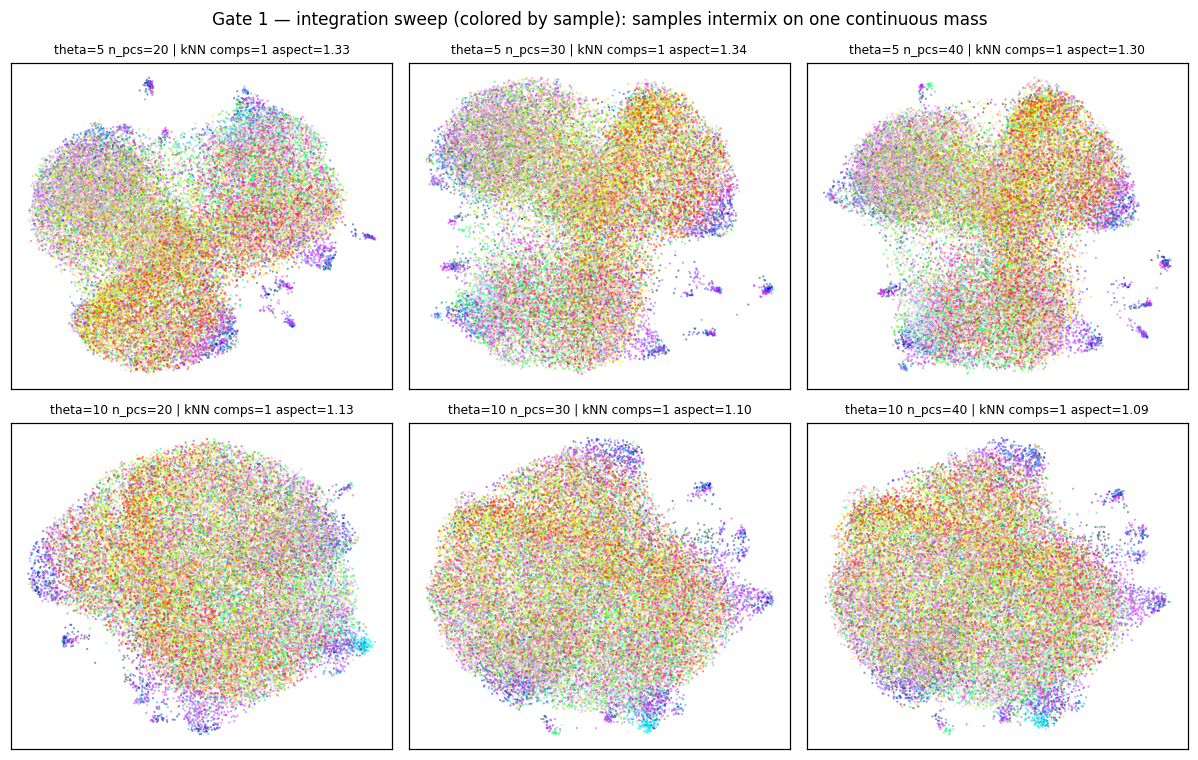

In [8]:
# Gate-1 embedding sweep: regenerate the UMAP at theta in {5,10} x n_pcs in {20,30,40}; inspect
# sample mixing + continuity ON THE EMBEDDING (not a scalar). Higher theta over-smooths to a round
# blob; theta=5 keeps an elongated, axis-bearing manifold while still fully intermixing samples.
grid_th, grid_pc = [5, 10], [20, 30, 40]
fig, axs = plt.subplots(len(grid_th), len(grid_pc), figsize=(11, 7))
codes = pd.Categorical(smp).codes
for i, th in enumerate(grid_th):
    adata.obsm['X_pca_harmony'] = sweep[th][1]
    for j, pc in enumerate(grid_pc):
        sc.pp.neighbors(adata, n_pcs=pc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
        sc.tl.umap(adata, spread=1.3, random_state=SEED)
        ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
        um = adata.obsm['X_umap']; c = um - um.mean(0); _, s, _ = np.linalg.svd(c, full_matrices=False)
        ax = axs[i, j]
        ax.scatter(um[:,0], um[:,1], c=codes, cmap='gist_ncar', s=2, alpha=.5, linewidths=0)
        ax.set_title('theta=%d n_pcs=%d | kNN comps=%d aspect=%.2f' % (th, pc, ncomp, s[0]/s[1]), fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Gate 1 — integration sweep (colored by sample): samples intermix on one continuous mass', fontsize=11)
fig.tight_layout(); plt.show()
print('every config: 1 kNN component, samples thoroughly intermixed; theta=5 keeps aspect ~1.4 '
      '(elongated developmental axis), theta=10 collapses to aspect ~1.1 (axis-less blob)')

In [9]:
# COMMIT the derived embedding: theta=5, n_pcs=30 (strong integration that preserves the axis).
THETA, N_PCS = 5, 30
adata.obsm['X_pca_harmony'] = sweep[THETA][1]
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('committed embedding: theta=%d, n_pcs=%d, n_neighbors=30, spread=1.3' % (THETA, N_PCS))

committed embedding: theta=5, n_pcs=30, n_neighbors=30, spread=1.3


In [10]:
# island removal: UMAP radius graph at 6x median NN distance; keep the largest connected
# component (strips only disconnected specks — conservative).
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 253 cells in 14 detached islands
after island removal: 32894 cells


In [11]:
# SUB-REGION BIOLOGY before the Gate-1 GO (Kürten lobe-identity fork): cell-cycle scoring +
# coarse Leiden lobes. Is any lobe a cycling compartment that must be scoped out of the trajectory?
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, [g for g in s_genes if g in adata.var_names],
                             [g for g in g2m_genes if g in adata.var_names])
adata.obs['cc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobes @ res 0.15:', adata.obs['lobe'].value_counts().to_dict())
print('cc_score per lobe:', adata.obs.groupby('lobe', observed=True)['cc_score'].mean().round(3).to_dict())
print('prolif score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('overall cc_score mean %.3f | cycling fraction (cc>0.1) %.3f'
      % (adata.obs['cc_score'].mean(), (adata.obs['cc_score']>0.1).mean()))
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)
print('-> single low-cycling body (no separate proliferation compartment) -> keep whole manifold (no scoping)')

lobes @ res 0.15: {'1': 21207, '0': 11687}
cc_score per lobe: {'0': -0.003, '1': 0.013}
prolif score per lobe: {'0': -0.08, '1': -0.04}
overall cc_score mean 0.007 | cycling fraction (cc>0.1) 0.051
-> single low-cycling body (no separate proliferation compartment) -> keep whole manifold (no scoping)


In [12]:
# module signatures (score_genes, union control pool) -> smoothed geography for orientation + Gate 1.
# Raw per-cell scores are the deliverable readout (03); smoothed scores are for reading geography.
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))
# graph-smooth the scores (3 hops of connectivity averaging)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('GLOBAL raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 69/81 genes present
pSom: 80/98 genes present
Crest: 101/104 genes present
GLOBAL raw module means (honest readout): {'Gast': -0.0217, 'pSom': 0.0144, 'Crest': 0.0013}


In [13]:
# read smoothed module geography + finalize the Gate-1 iLISI/continuity readout.
print('smoothed module geography (Pearson on smoothed scores):')
for a, b in [('Gast_sm','pSom_sm'), ('Gast_sm','Crest_sm'), ('pSom_sm','Crest_sm')]:
    print('  %s vs %s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], smp))
ncomp_knn, _ = connected_components(adata.obsp['connectivities'], directed=False)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _, s, _ = np.linalg.svd(c, full_matrices=False)
print('iLISI median: pre-Harmony %.2f -> post-Harmony(theta=%d) %.2f of %d samples'
      % (il_pre, THETA, il_post, nsamp))
print('kNN graph connected components: %d (=1 -> one continuous manifold) | UMAP aspect %.2f'
      % (ncomp_knn, s[0]/s[1]))
print('GATE 1 = GO: samples intermix per-neighbourhood (iLISI 1.0 -> %.1f) on one continuous, '
      'low-cycling manifold' % il_post)

smoothed module geography (Pearson on smoothed scores):
  Gast_sm vs pSom_sm: r = +0.28
  Gast_sm vs Crest_sm: r = -0.73
  pSom_sm vs Crest_sm: r = -0.65
iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=5) 12.46 of 54 samples
kNN graph connected components: 1 (=1 -> one continuous manifold) | UMAP aspect 1.42
GATE 1 = GO: samples intermix per-neighbourhood (iLISI 1.0 -> 12.5) on one continuous, low-cycling manifold


saved samples.pdf


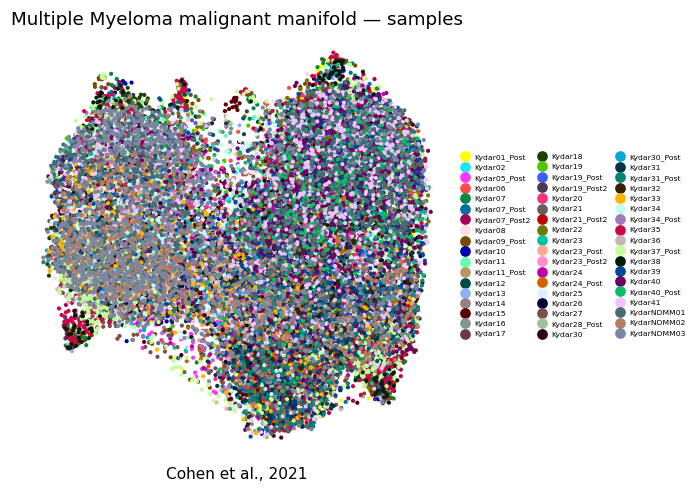

In [14]:
# save samples.pdf — single sample-colored manifold UMAP (reference style: one panel + legend).
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=30, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol=3, frameon=False, loc='center left',
          bbox_to_anchor=(1.0, 0.5), columnspacing=.5, handletextpad=.25, fontsize=5)
ax.set_title('Multiple Myeloma malignant manifold — samples', size=12)
ax.text(.5, -.05, 'Cohen et al., 2021', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')

In [15]:
# tidy obs dtypes and save processed.h5ad
protect = {'sample','patient','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','phase'}
for cix in adata.obs.columns:
    if cix in protect:
        adata.obs[cix] = adata.obs[cix].astype(str).astype('category'); continue
    col = adata.obs[cix]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cix] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (32894, 31585)
